<div dir="rtl">

# מתכנן מטלות: חקירת הנתונים (EDA)
אבן דרך 2 · וייב קודינג עם קלוד · אוניברסיטת אריאל · סמסטר א' תשפ"ז

| | |
|---|---|
| **הבעיה** | סטודנטים דוחים מטלות לרגע האחרון ומאחרים. אנחנו בונים **מתכנן מטלות** שמשבץ את המטלות בלוח שבועי, ומסמן לכל מטלה את **הסיכון שתוגש באיחור** (ירוק, צהוב, אדום) |
| **למי** | סטודנטים שרוצים לתכנן את השבוע ולא לאחר |
| **ה-y** | `is_late`: האם עבודה כתובה הוגשה אחרי יום הדדליין (1) או עד יום הדדליין (0). רק מבין העבודות שהוגשו |
| **הנתונים** | OULAD: נתונים אמיתיים של האוניברסיטה הפתוחה הבריטית, 2013 עד 2014. ‏124,232 עבודות שהיה צריך להגיש, של 24,986 סטודנטים |

### 💡 התובנה
**גילינו שמי שאיחר בעבודה אחת מאחר גם בעבודה הבאה ב-41% מהמקרים, כמעט פי 3 ממי שהגיש אותה בזמן (14%).**
למשתמש זה אומר: איחור אחד הוא סימן אזהרה. אחרי איחור, האפליקציה תסמן את המטלה הבאה בסיכון גבוה ותמליץ להתחיל מוקדם יותר.

### 🎯 ה-baseline
**"כולם מגישים בזמן" צודק ב-83.2% מההגשות, אבל לא מזהה אף מאחר (0%).**
זה המספר שהמודל ב-M3 צריך לנצח. מכיוון שהנתונים לא מאוזנים, נמדוד את המודל גם ב-AUC ובכמה מאחרים הוא מזהה, ולא רק בדיוק.

**סדר המחברת (גם סדר הפיץ'):** 1. הנתונים ומה תיקנו · 2. סוגי העמודות · 3. איכות · 4. התפלגויות · 5. קורלציה ובדיקת דליפה · 6. baseline · 7. סיכום

</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", 30)

# One color per group, the same everywhere in the notebook
C_ON_TIME, C_LATE, C_NOT_SUB = "#2a78d6", "#eb6834", "#1baf7a"
C_FIRST, C_LEAK = "#9a9990", "#e34948"
INK, GRID = "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.figsize": (8, 3.8), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": INK, "axes.titlecolor": "#0b0b0b",
    "xtick.color": INK, "ytick.color": INK, "axes.titleweight": "bold", "axes.titlesize": 11,
    "font.size": 9.5, "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True,
})


def label_bars(ax, bars, fmt="{:.1f}%"):
    """Write the value above each bar."""
    for b in bars:
        ax.annotate(fmt.format(b.get_height()), (b.get_x() + b.get_width() / 2, b.get_height()),
                    ha="center", va="bottom", xytext=(0, 2), textcoords="offset points", color=INK)


df = pd.read_csv("data/tma_submissions.csv")       # main table: one row per student and written assignment
clicks = pd.read_csv("data/clicks_by_day.csv")     # summary of 10.6 million click records
submitted = df[df["is_late"].notna()].copy()       # only assignments that were submitted (where y exists)

print(f"Main table:  {len(df):,} rows x {df.shape[1]} columns | students: {df['id_student'].nunique():,}")
print(f"Submitted:   {len(submitted):,} rows (these have a y)")
print(f"Clicks file: {len(clicks):,} rows")
df.head()

Main table:  124,232 rows x 24 columns | students: 24,986
Submitted:   96,708 rows (these have a y)
Clicks file: 14,310 rows


,id_student,code_module,code_presentation,id_assessment,domain,year,start_month,tma_number,n_tmas,deadline_day,weight,studied_credits,gender,age_band,highest_education,region,imd_band,disability,date_submitted,days_from_deadline,status,is_late,prev_status,prev_late_rate
0,11391,AAA,2013J,1752,Social Sciences,2013,October,1,5,19,10.0,240,M,55<=,HE Qualification,East Anglian Region,90-100%,N,18.0,-1.0,on_time,0.0,first,NaN
1,11391,AAA,2013J,1753,Social Sciences,2013,October,2,5,54,20.0,240,M,55<=,HE Qualification,East Anglian Region,90-100%,N,53.0,-1.0,on_time,0.0,on_time,0.0
2,11391,AAA,2013J,1754,Social Sciences,2013,October,3,5,117,20.0,240,M,55<=,HE Qualification,East Anglian Region,90-100%,N,115.0,-2.0,on_time,0.0,on_time,0.0
3,11391,AAA,2013J,1755,Social Sciences,2013,October,4,5,166,20.0,240,M,55<=,HE Qualification,East Anglian Region,90-100%,N,164.0,-2.0,on_time,0.0,on_time,0.0
4,11391,AAA,2013J,1756,Social Sciences,2013,October,5,5,215,30.0,240,M,55<=,HE Qualification,East Anglian Region,90-100%,N,212.0,-3.0,on_time,0.0,on_time,0.0


<div dir="rtl">

## 1. הנתונים ומה תיקנו

**המקור:** [OULAD](https://archive.ics.uci.edu/dataset/349/open+university+learning+analytics+dataset), האוניברסיטה הפתוחה הבריטית. רישיון CC BY 4.0. **נתונים אמיתיים, לא סינתטיים.**
המאגר המקורי הוא 7 טבלאות נפרדות. אף טבלה לא אומרת אם עבודה הוגשה באיחור: את זה חישבנו בעצמנו. הסקריפט `clean_oulad.py` מחבר את הטבלאות לטבלה אחת: **שורה לכל סטודנט ולכל עבודה כתובה שהוא היה צריך להגיש.**

| מה עשינו | כמה שורות | למה |
|---|---|---|
| לקחנו רק עבודות כתובות (TMA) | | במבחנים הממוחשבים (CMA) ‏47% "מאחרים". כנראה הדדליין שם לא מחייב |
| חיברנו כל רישום לקורס עם כל עבודה בקורס | 162,418 | ככה רואים גם עבודות שלא הוגשו |
| הוצאנו מי שביטל את ההרשמה ביום הדדליין או לפניו | ‏36,910- | הוא עזב את הקורס, ולא היה אמור להגיש |
| הוצאנו מי שנרשם אחרי הדדליין | ‏42- | הוא לא יכול היה להגיש |
| הוצאנו ציונים שהועברו מניסיון קודם (`is_banked`) | ‏1,234- | זו לא הגשה אמיתית בסמסטר הזה |
| **התוצאה** | **124,232** | |

**עמודות שחישבנו:**
- `is_late` (ה-y): יום ההגשה פחות הדדליין. **הגשה ביום הדדליין עצמו נחשבת בזמן**, כי בנתונים אין שעה.
- `prev_status`, ‏`prev_late_rate`: מה קרה בעבודות **הקודמות** של אותו סטודנט באותו קורס. רק מה שהיה ידוע לפני הדדליין הנוכחי.

**עמודות שלא הכנסנו, בגלל דליפת מידע:** התוצאה הסופית בקורס (`final_result`) והציון של העבודה. שתיהן ידועות רק אחרי ההגשה.

**קובץ הקליקים** (`studentVle.csv`, ‏433MB) גדול מהמגבלה של GitHub. הסקריפט `summarize_clicks.py` מסכם אותו לקובץ קטן, `clicks_by_day.csv`: כמה סטודנטים נכנסו לאתר הקורס בכל יום סביב הדדליין.

**ה-y חושב מנוסחה** (יום ההגשה פחות הדדליין). לכן עמודות יום ההגשה **לא ייכנסו למודל**, אחרת הוא פשוט ילמד את הנוסחה (ראו בדיקת הדליפה בסעיף 5).

</div>

In [2]:
# Does the target have both answers? (a model needs both "yes" and "no" to learn)
print(submitted["is_late"].value_counts().rename({0.0: "0 = on time", 1.0: "1 = late"}).to_string())

is_late
0 = on time    80449
1 = late       16259


<div dir="rtl">

**מסקנה:** ב-y יש את שני הסוגים: 80,449 הגשות בזמן ו-16,259 באיחור. יש ממה ללמוד.

</div>

<div dir="rtl">

## 2. שאלה 1: סוגי העמודות
לכל עמודה: מה הסוג שלה באמת (לא רק איך היא שמורה), וממה היא תשמש. **הכלל שלנו: למודל נכנס רק מה שסטודנט יכול להזין באפליקציה.**

</div>

In [3]:
roles = {
    "id_student":         ("identifier",            "ID, not a feature"),
    "code_module":        ("categorical (7)",       "EDA only: British courses"),
    "code_presentation":  ("categorical (4)",       "EDA only"),
    "id_assessment":      ("identifier",            "ID, not a feature"),
    "domain":             ("binary",                "EDA only"),
    "year":               ("categorical (2 years)", "EDA only"),
    "start_month":        ("binary",                "EDA only"),
    "tma_number":         ("ordinal (1-6)",         "MODEL INPUT"),
    "n_tmas":             ("numeric",               "EDA only"),
    "deadline_day":       ("numeric (day)",         "not used: same info as tma_number"),
    "weight":             ("numeric (%)",           "MODEL INPUT"),
    "studied_credits":    ("numeric",               "MODEL INPUT"),
    "gender":             ("binary",                "EDA only: fairness"),
    "age_band":           ("ordinal (3)",           "EDA only: fairness"),
    "highest_education":  ("ordinal (5)",           "EDA only: fairness"),
    "region":             ("categorical (13)",      "EDA only: UK regions"),
    "imd_band":           ("ordinal (10)",          "EDA only: fairness"),
    "disability":         ("binary",                "EDA only: fairness"),
    "date_submitted":     ("numeric (day)",         "LEAKAGE: known only after submitting"),
    "days_from_deadline": ("numeric (days)",        "LEAKAGE: y is computed from it"),
    "status":             ("categorical (3)",       "LEAKAGE: y with 3 values"),
    "is_late":            ("binary",                "TARGET (y)"),
    "prev_status":        ("categorical (4)",       "MODEL INPUT"),
    "prev_late_rate":     ("numeric (0-1)",         "MODEL INPUT"),
}
types = pd.DataFrame({
    "stored as": df.dtypes.astype(str),
    "real kind": [roles[c][0] for c in df.columns],
    "unique values": df.nunique(),
    "example": df.apply(lambda s: s.dropna().iloc[0]),
    "role": [roles[c][1] for c in df.columns],
})
types

,stored as,real kind,unique values,example,role
id_student,int64,identifier,24986,11391,"ID, not a feature"
code_module,str,categorical (7),7,AAA,EDA only: British courses
code_presentation,str,categorical (4),4,2013J,EDA only
id_assessment,int64,identifier,106,1752,"ID, not a feature"
domain,str,binary,2,Social Sciences,EDA only
year,int64,categorical (2 years),2,2013,EDA only
start_month,str,binary,2,October,EDA only
tma_number,int64,ordinal (1-6),6,1,MODEL INPUT
n_tmas,int64,numeric,4,5,EDA only
deadline_day,int64,numeric (day),53,19,not used: same info as tma_number


In [4]:
types["role"].str.split(":").str[0].value_counts().to_frame("columns")

,columns
role,
EDA only,12
MODEL INPUT,5
LEAKAGE,3
"ID, not a feature",2
not used,1
TARGET (y),1


<div dir="rtl">

**מסקנות:**
- **מספר זה לא תמיד מספר.** ‏`tma_number` כתוב כמספר, אבל הוא סדר (עבודה ראשונה, שנייה...). ‏`year` כתוב כמספר, אבל יש בו רק 2 ערכים, כלומר קטגוריה. ‏`id_student` ו-`id_assessment` הם מזהים, ואסור להכניס אותם למודל כמספרים.
- **5 עמודות ייכנסו למודל:** משקל העבודה, מספר העבודה בקורס, העומס, ושתי עמודות ההיסטוריה. את כולן סטודנט באריאל יכול להזין.
- **3 עמודות הן דליפה** (יום ההגשה, ההפרש מהדדליין והסטטוס): הן ידועות רק אחרי ההגשה, וה-y מחושב מהן.
- **הנתונים הדמוגרפיים** (מגדר, גיל, מוגבלות, מדד עוני) נשארים לחקירה בלבד: הם בריטיים, ושימוש בהם לחיזוי הוא בעייתי מבחינת הוגנות.

</div>

<div dir="rtl">

## 3. שאלה 2: איכות
חוסרים, כפילויות, ערכים שגויים וחריגים, ומה עשינו עם כל אחד.

</div>

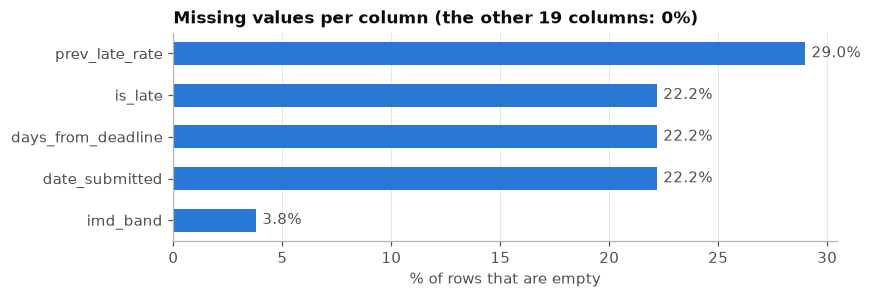

In [5]:
missing = (df.isna().mean() * 100).round(1)
missing = missing[missing > 0].sort_values()

fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(missing.index, missing.values, color=C_ON_TIME, height=0.55)
for b in bars:
    ax.annotate(f"{b.get_width():.1f}%", (b.get_width(), b.get_y() + b.get_height() / 2),
                xytext=(4, 0), textcoords="offset points", va="center", color=INK)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("% of rows that are empty")
ax.set_title(f"Missing values per column (the other {df.shape[1] - len(missing)} columns: 0%)", loc="left")
plt.tight_layout(); plt.show()

<div dir="rtl">

**מסקנה:** רק 5 עמודות עם תאים ריקים, **ו-4 מהן ריקות בכוונה, לא חסרות:**
- `date_submitted`, ‏`days_from_deadline` ו-`is_late` ריקים בדיוק ב-22.2%: **אלה העבודות שלא הוגשו.** לא ממלאים ב-0, כי 0 אומר "הוגש ביום הדדליין".
- `prev_late_rate` ריק ב-29%: **אין עבודה קודמת שהוגשה** (בעיקר העבודה הראשונה בקורס). לא ממלאים ב-0, כי 0 אומר "הגיש הכול בזמן". ‏`prev_status` אומר במפורש `first`.
- **החוסר האמיתי היחיד:** ‏`imd_band` (מדד העוני של האזור), 3.8%. משאירים ריק, כי העמודה לא נכנסת למודל.

</div>

In [6]:
checks = pd.Series({
    "Duplicate rows (same student + same assignment)":
        df.duplicated(["id_student", "id_assessment"]).sum(),
    "Rows where status and is_late disagree":
        ((df["status"] == "late") != (df["is_late"] == 1)).sum()
        + ((df["status"] == "not_submitted") != df["is_late"].isna()).sum(),
    "Rows of assignments that weigh 0% of the grade":
        (df["weight"] == 0).sum(),
    "Students with more than 240 credits (120 = full-time year)":
        df.loc[df["studied_credits"] > 240, "id_student"].nunique(),
    "Submissions more than 30 days BEFORE the deadline":
        (df["days_from_deadline"] < -30).sum(),
    "Submissions more than 60 days AFTER the deadline":
        (df["days_from_deadline"] > 60).sum(),
    "imd_band written as '10-20' (no % sign, unlike the rest)":
        (df["imd_band"] == "10-20").sum(),
}, name="count")
checks.to_frame()

,count
Duplicate rows (same student + same assignment),0
Rows where status and is_late disagree,0
Rows of assignments that weigh 0% of the grade,8819
Students with more than 240 credits (120 = full-time year),69
Submissions more than 30 days BEFORE the deadline,167
Submissions more than 60 days AFTER the deadline,97
"imd_band written as '10-20' (no % sign, unlike the rest)",12651


In [7]:
# Where are the 0% assignments?
df[df["weight"] == 0].groupby(["code_module", "code_presentation", "tma_number"]).size().to_frame("rows")

rows
code_module code_presentation tma_number      
BBB         2014J             1           1803
GGG         2013J             1            919
                              2            909
                              3            896
            2014B             1            789
                              2            777
                              3            754
            2014J             1            691
                              2            652
                              3            629

<div dir="rtl">

**מסקנה, ומה החלטנו לגבי כל דבר:**

| מה מצאנו | ההחלטה | למה |
|---|---|---|
| **אין כפילויות**, ו-`status` מתאים ל-`is_late` בכל השורות | אין מה לתקן | הבדיקה עברה |
| **עבודות במשקל 0%:** כל העבודות בקורס GGG, וגם העבודה הראשונה ב-BBB בסמסטר 2014J | משאירים | זה נתון אמיתי, לא חסר. גם באריאל יש מטלות ששוות 0% |
| **69 סטודנטים עם יותר מ-240 קרדיטים** (פי 2 משנה מלאה) | משאירים | כנראה טעות במקור, אבל שאר הנתונים בשורות שלהם תקינים |
| **הגשות קיצוניות:** 167 יותר מחודש לפני הדדליין, ו-97 באיחור של יותר מחודשיים | משאירים | הסטטוס שלהן נכון (בזמן / באיחור). בגרפים מציגים טווח מוגבל |
| **`imd_band` כתוב "10-20" בלי סימן אחוז** | משאירים | העמודה לא נכנסת למודל. בגרפים כותבים "10-20%" |

</div>

<div dir="rtl">

## 4. שאלה 3: התפלגויות
אילו ערכים יש, כמה מכל אחד, ובמיוחד: **האם עמודת התשובה מאוזנת?**

</div>

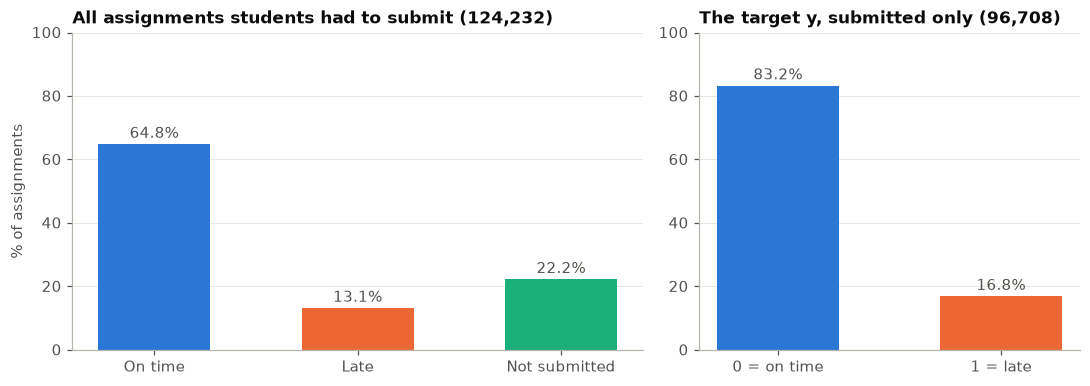

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [3, 2]})

st = df["status"].value_counts(normalize=True).reindex(["on_time", "late", "not_submitted"]) * 100
bars = axes[0].bar(["On time", "Late", "Not submitted"], st.values,
                   color=[C_ON_TIME, C_LATE, C_NOT_SUB], width=0.55)
label_bars(axes[0], bars)
axes[0].set_title(f"All assignments students had to submit ({len(df):,})", loc="left")
axes[0].set_ylabel("% of assignments")

yv = submitted["is_late"].value_counts(normalize=True).sort_index() * 100
bars = axes[1].bar(["0 = on time", "1 = late"], yv.values, color=[C_ON_TIME, C_LATE], width=0.55)
label_bars(axes[1], bars)
axes[1].set_title(f"The target y, submitted only ({len(submitted):,})", loc="left")
for ax in axes:
    ax.set_ylim(0, 100)
plt.tight_layout(); plt.show()

<div dir="rtl">

**מסקנה: הנתונים לא מאוזנים.** מבין העבודות שהוגשו, רק **16.8%** באיחור. המשמעות:
- מודל "עצלן" שתמיד עונה "בזמן" יקבל 83% דיוק בלי ללמוד כלום. לכן **דיוק לבד הוא מדד מטעה**, וב-M3 נמדוד גם AUC וכמה מאחרים המודל מזהה.
- **22% לא הוגשו בכלל.** אלה לא נכנסים ל-y: אי-הגשה היא בעיקר נשירה מהקורס, וזו תופעה אחרת מאיחור.

</div>

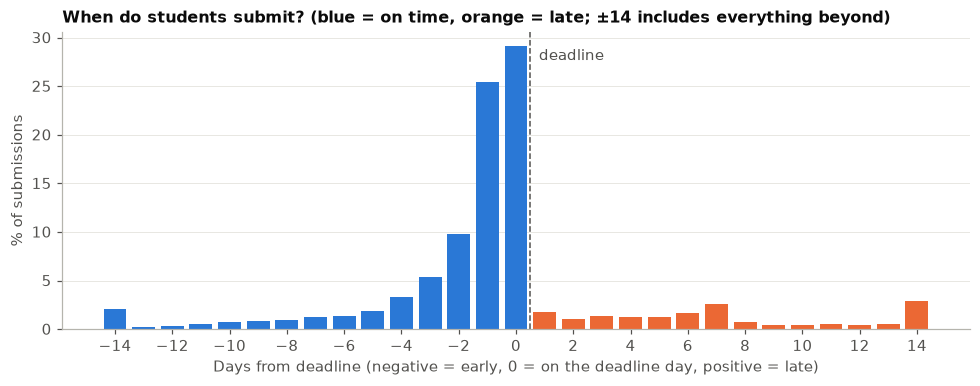

Median: -1 day(s) from the deadline
Submitted ON the deadline day: 29.2%
Late by 1-3 days: 4.1%   late by more than a week: 5.9%


In [9]:
d = submitted["days_from_deadline"].clip(-14, 14)          # everything beyond ±14 is stacked on the edges
share = d.value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(share.index, share.values, width=0.8,
       color=[C_LATE if x > 0 else C_ON_TIME for x in share.index])
ax.axvline(0.5, color=INK, lw=1, ls="--")
ax.text(0.8, share.max() * 0.95, "deadline", color=INK)
ax.set_xticks(range(-14, 15, 2))
ax.set_xlabel("Days from deadline (negative = early, 0 = on the deadline day, positive = late)")
ax.set_ylabel("% of submissions")
ax.set_title("When do students submit? (blue = on time, orange = late; ±14 includes everything beyond)", loc="left", fontsize=10.5)
plt.tight_layout(); plt.show()

print(f"Median: {submitted['days_from_deadline'].median():.0f} day(s) from the deadline")
print(f"Submitted ON the deadline day: {(submitted['days_from_deadline'] == 0).mean() * 100:.1f}%")
print(f"Late by 1-3 days: {submitted['days_from_deadline'].between(1, 3).mean() * 100:.1f}%   "
      f"late by more than a week: {(submitted['days_from_deadline'] > 7).mean() * 100:.1f}%")

<div dir="rtl">

**מסקנה: מגישים ברגע האחרון.** בחציון מגישים **יום אחד לפני הדדליין**, ו-**29%** מגישים ביום הדדליין עצמו. ההתפלגות של המאחרים ארוכה: חלק מאחרים ביום-יומיים, אבל ‏5.9% מאחרים ביותר משבוע. זה מתאים לרעיון של האפליקציה: לעזור להתחיל מוקדם.

</div>

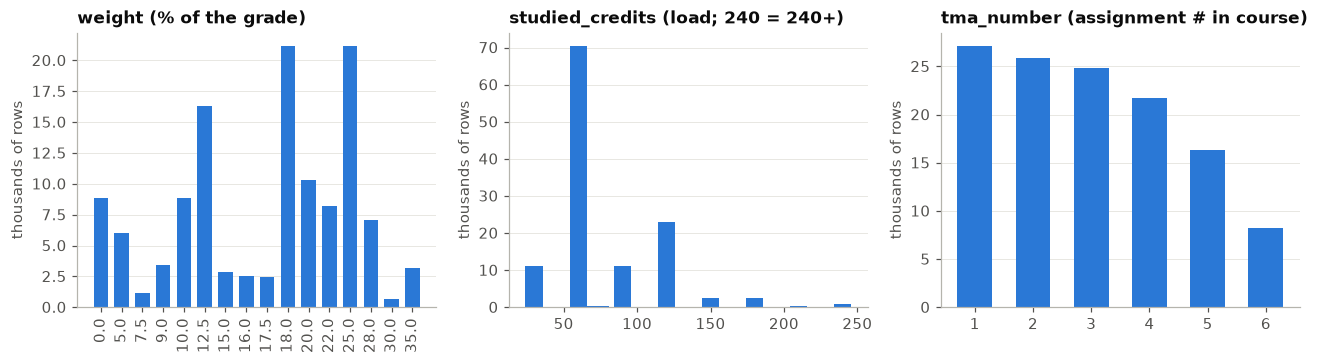

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))

w = df["weight"].value_counts().sort_index()
axes[0].bar(w.index.astype(str), w.values / 1000, color=C_ON_TIME, width=0.7)
axes[0].set_title("weight (% of the grade)", loc="left")
axes[0].tick_params(axis="x", rotation=90)

c = df["studied_credits"].clip(upper=240).value_counts().sort_index()
axes[1].bar(c.index, c.values / 1000, color=C_ON_TIME, width=12)
axes[1].set_title("studied_credits (load; 240 = 240+)", loc="left")

n = df["tma_number"].value_counts().sort_index()
axes[2].bar(n.index, n.values / 1000, color=C_ON_TIME, width=0.6)
axes[2].set_title("tma_number (assignment # in course)", loc="left")

for ax in axes:
    ax.set_ylabel("thousands of rows")
plt.tight_layout(); plt.show()

<div dir="rtl">

**מסקנה, על הקלטים של המודל:**
- **משקל:** בעיקר בין 10% ל-25%. ‏0% מופיע הרבה בגלל קורס GGG (ראו סעיף איכות).
- **עומס:** רוב הסטודנטים לומדים 60 קרדיטים (חצי משרה). מעט מאוד מעל 120. כלומר על סטודנטים עמוסים יש פחות נתונים.
- **מספר העבודה:** כמעט לכל הקורסים יש 5 עבודות או יותר, ולכן העבודה השישית נדירה.

</div>

<div dir="rtl">

## 5. שאלה 4: קורלציה ובדיקת דליפה
אילו עמודות זזות יחד, ומה הקשר של כל עמודה ל-y. **קורלציה גבוהה מדי ל-y היא חשד לדליפה:** סימן שהעמודה כבר מכילה את התשובה.

</div>

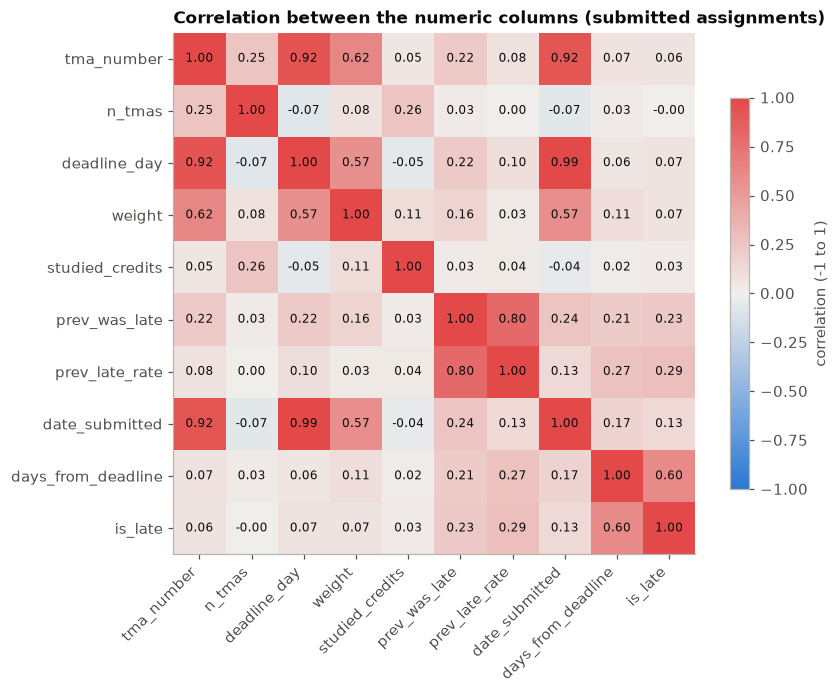

In [11]:
submitted["prev_was_late"] = (submitted["prev_status"] == "late").astype(int)   # yes/no version of prev_status
cols = ["tma_number", "n_tmas", "deadline_day", "weight", "studied_credits",
        "prev_was_late", "prev_late_rate", "date_submitted", "days_from_deadline", "is_late"]
corr = submitted[cols].corr()

cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(8, 6.4))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)), cols)
ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color="#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.75, label="correlation (-1 to 1)")
ax.set_title("Correlation between the numeric columns (submitted assignments)", loc="left")
plt.tight_layout(); plt.show()

<div dir="rtl">

**מסקנה: אילו עמודות זזות יחד**
- **`deadline_day` ו-`tma_number`: ‏0.92.** זה אותו מידע: ככל שהעבודה מאוחרת יותר בקורס, הדדליין שלה רחוק יותר מתחילת הקורס. **למודל נכניס רק את `tma_number`.**
- **`date_submitted` ו-`deadline_day`: ‏0.99.** כמעט כולם מגישים סביב הדדליין, ולכן יום ההגשה כמעט זהה ליום הדדליין.
- **`weight` ו-`tma_number`: ‏0.62.** העבודות המאוחרות בקורס שוקלות יותר.
- **שתי עמודות ההיסטוריה** (`prev_was_late`, ‏`prev_late_rate`): ‏0.80. הן קשורות, אבל לא זהות: אחת מסתכלת רק על העבודה הקודמת, והשנייה על כל העבודות הקודמות. ב-M3 נבדוק אם צריך את שתיהן.

</div>

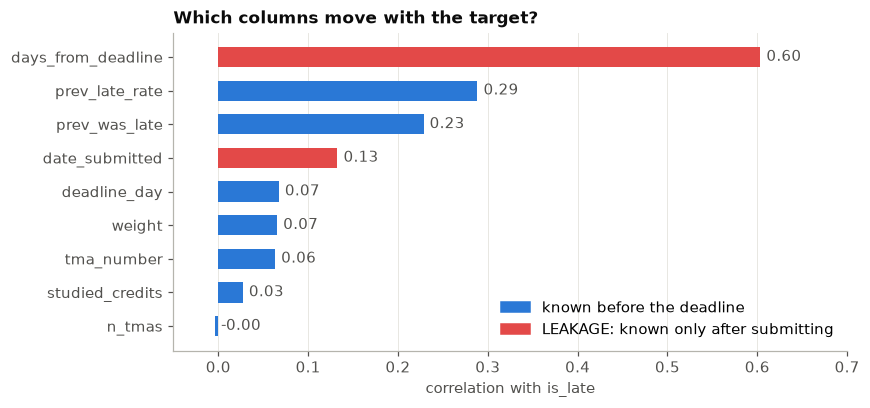

is_late,0.0,1.0
status,,
late,0,16259
on_time,80449,0


In [12]:
r = corr["is_late"].drop("is_late").sort_values()
leak = {"date_submitted", "days_from_deadline"}

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(r.index, r.values, height=0.6,
               color=[C_LEAK if c in leak else C_ON_TIME for c in r.index])
for b in bars:
    ax.annotate(f"{b.get_width():.2f}", (b.get_width(), b.get_y() + b.get_height() / 2),
                xytext=(4, 0), textcoords="offset points", va="center", color=INK)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlim(-0.05, 0.7)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C_ON_TIME), plt.Rectangle((0, 0), 1, 1, color=C_LEAK)],
          labels=["known before the deadline", "LEAKAGE: known only after submitting"],
          loc="lower right", frameon=False)
ax.set_xlabel("correlation with is_late")
ax.set_title("Which columns move with the target?", loc="left")
plt.tight_layout(); plt.show()

# status is text, so it is not in the chart. It matches y perfectly:
pd.crosstab(submitted["status"], submitted["is_late"])

<div dir="rtl">

**מסקנה: בדיקת דליפה**
- **`days_from_deadline` (‏0.60) הוא דליפה.** ה-y מחושב ממנו: חיובי = איחור. הקורלציה לא מגיעה ל-0.98 רק כי ה-y הוא כן/לא, אבל העמודה **מכילה את התשובה**. כך גם `date_submitted`, ו-`status`, שמתאים ל-y ב-100% (הטבלה למעלה). **שלושתן לא ייכנסו למודל.**
- **בלי הדליפות, הקשר הכי חזק הוא להיסטוריה:** ‏`prev_late_rate` (‏0.29) ו-`prev_was_late` (‏0.23). שתיהן ידועות **לפני** הדדליין, ולכן מותרות.
- **משקל, מספר העבודה ועומס: קשר חלש** (0.03 עד 0.07). לבד הן לא יספיקו, וזה צפוי: איחור תלוי בהרבה דברים שאין בנתונים.
- קורלציה מודדת רק קשר בקו ישר. בגרפים הבאים בודקים את הקשר ישירות: אחוז האיחור בכל קבוצה.

</div>

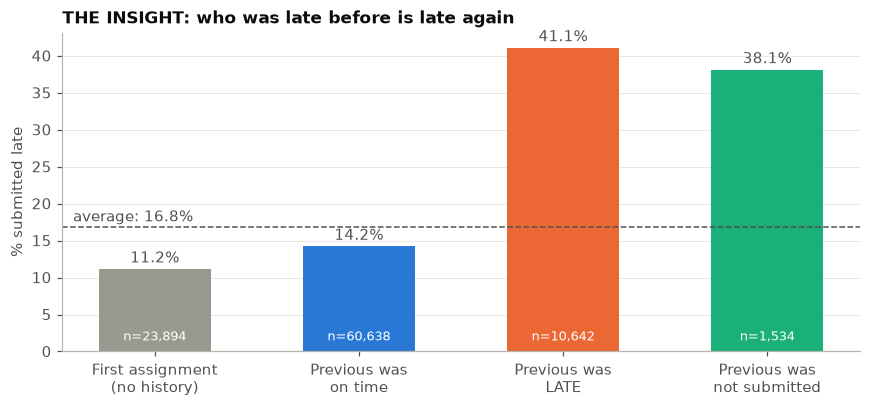

In [13]:
order = ["first", "on_time", "late", "not_submitted"]
names = ["First assignment\n(no history)", "Previous was\non time", "Previous was\nLATE", "Previous was\nnot submitted"]
rate = submitted.groupby("prev_status")["is_late"].mean().reindex(order) * 100
count = submitted["prev_status"].value_counts().reindex(order)

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(names, rate.values, width=0.55, color=[C_FIRST, C_ON_TIME, C_LATE, C_NOT_SUB])
label_bars(ax, bars)
for i, n in enumerate(count.values):
    ax.text(i, 1.5, f"n={n:,}", ha="center", color="white", fontsize=8.5)
ax.axhline(submitted["is_late"].mean() * 100, color=INK, lw=1, ls="--")
ax.text(-0.4, submitted["is_late"].mean() * 100 + 0.8, "average: 16.8%", color=INK, ha="left")
ax.set_ylabel("% submitted late")
ax.set_title("THE INSIGHT: who was late before is late again", loc="left")
plt.tight_layout(); plt.show()

<div dir="rtl">

**מסקנה (זו התובנה שלנו):** מי שאיחר בעבודה הקודמת מאחר שוב ב-**41%**, לעומת **14%** אצל מי שהגיש אותה בזמן. **כמעט פי 3.** בעבודה הראשונה בקורס, כשאין היסטוריה, רק 11% מאחרים.
מי שלא הגיש את העבודה הקודמת ובכל זאת הגיש את הנוכחית מאחר ב-38%: גם הוא "בפיגור". לכן **ההיסטוריה היא הקלט הכי חשוב למודל**, והאפליקציה תשאל משתמש חדש: "בסמסטר שעבר, כמה פעמים הגשת באיחור?".

</div>

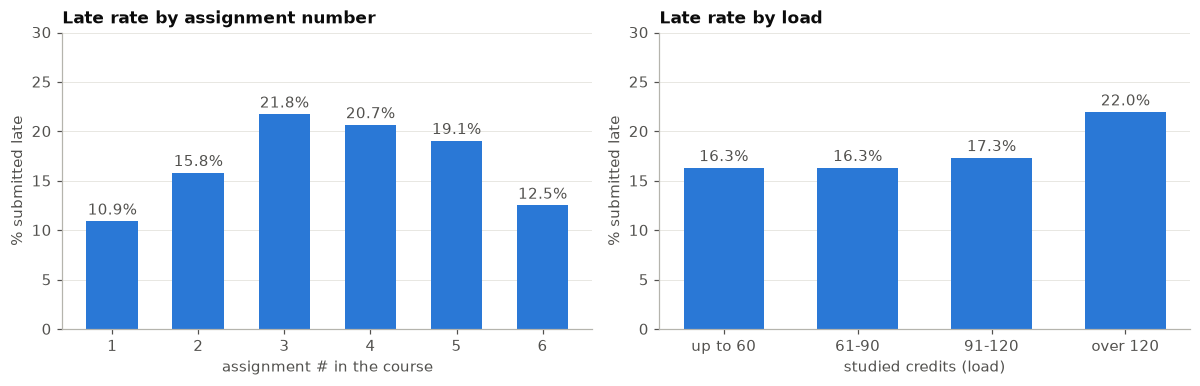

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

by_n = submitted.groupby("tma_number")["is_late"].mean() * 100
bars = axes[0].bar(by_n.index, by_n.values, color=C_ON_TIME, width=0.6)
label_bars(axes[0], bars)
axes[0].set_xlabel("assignment # in the course")
axes[0].set_title("Late rate by assignment number", loc="left")

load = pd.cut(submitted["studied_credits"], [0, 60, 90, 120, 10_000],
              labels=["up to 60", "61-90", "91-120", "over 120"])
by_load = submitted.groupby(load, observed=True)["is_late"].mean() * 100
bars = axes[1].bar(by_load.index.astype(str), by_load.values, color=C_ON_TIME, width=0.6)
label_bars(axes[1], bars)
axes[1].set_xlabel("studied credits (load)")
axes[1].set_title("Late rate by load", loc="left")

for ax in axes:
    ax.set_ylabel("% submitted late"); ax.set_ylim(0, 30)
plt.tight_layout(); plt.show()

<div dir="rtl">

**מסקנה:**
- **אמצע הסמסטר הוא השיא:** בעבודה הראשונה 11% מאחרים, בשלישית 22%. אחר כך יורד קצת. כנראה שבאמצע הסמסטר העומס מצטבר. בעבודה השישית יש מעט נתונים (רק בקורסים עם 6 עבודות).
- **עומס משפיע רק בקצה:** עד 120 קרדיטים כמעט אין הבדל (16% עד 17%), ומעל 120 קופץ ל-22%. זה קשר שהקורלציה (0.03) פספסה, כי הוא לא בקו ישר.

</div>

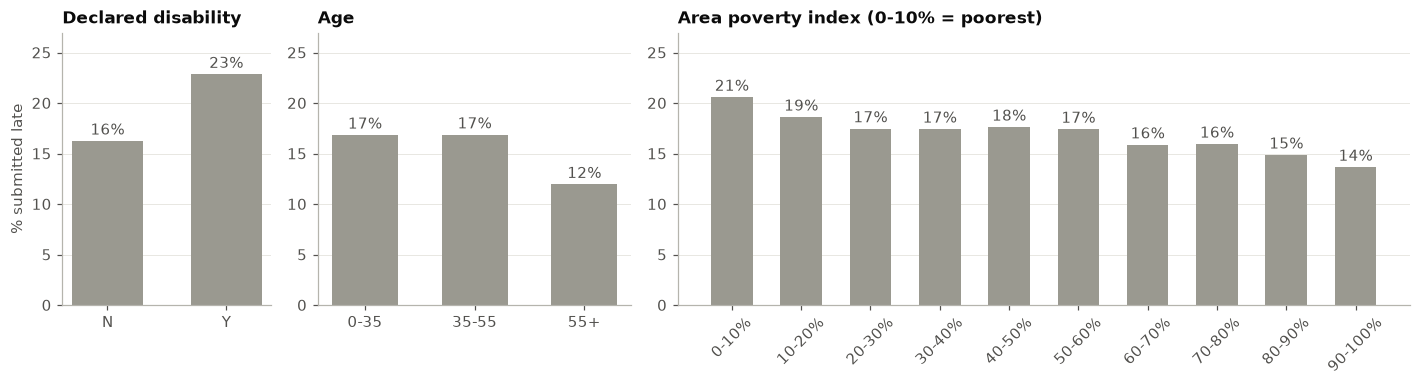

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2, 3, 7]})
for ax, col, title in [(axes[0], "disability", "Declared disability"),
                       (axes[1], "age_band", "Age"),
                       (axes[2], "imd_band", "Area poverty index (0-10% = poorest)")]:
    rate = submitted.groupby(col)["is_late"].mean() * 100
    labels = [s if s.endswith("%") or col != "imd_band" else s + "%" for s in rate.index]
    labels = [s.replace("55<=", "55+") for s in labels]
    bars = ax.bar(labels, rate.values, color=C_FIRST, width=0.6)
    label_bars(ax, bars, "{:.0f}%")
    ax.set_title(title, loc="left"); ax.set_ylim(0, 27)
    ax.tick_params(axis="x", rotation=45 if col == "imd_band" else 0)
axes[0].set_ylabel("% submitted late")
plt.tight_layout(); plt.show()

<div dir="rtl">

**מסקנה:** יש הבדלים בין קבוצות: סטודנטים עם מוגבלות מוצהרת מאחרים יותר (23% לעומת 16%), וככל שהאזור עני יותר מאחרים יותר (21% באזורים העניים לעומת 14% בעשירים).
**ובכל זאת, הנתונים האלה לא ייכנסו למודל:**
- **הוגנות:** מודל שמסמן סטודנט באדום בגלל מוגבלות או בגלל השכונה שלו הוא לא הוגן.
- **התאמה:** אלה אזורים ומדדים בריטיים, ואין להם מקבילה באריאל.

הם כאן רק כדי להבין את הנתונים.

</div>

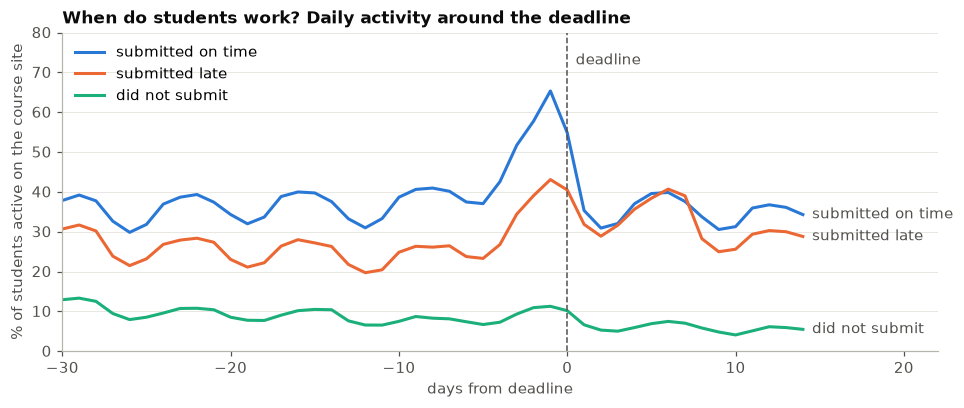

Share of the month's clicks made in the last 3 days before the deadline: 15.3% (if work were spread evenly: 9.7%)


In [16]:
pooled = clicks.groupby(["group", "days_from_deadline"])[["active_students", "students_in_group"]].sum()
active = (pooled["active_students"] / pooled["students_in_group"] * 100).unstack(0)

fig, ax = plt.subplots(figsize=(9, 3.8))
for g, color, name in [("on_time", C_ON_TIME, "submitted on time"),
                       ("late", C_LATE, "submitted late"),
                       ("not_submitted", C_NOT_SUB, "did not submit")]:
    ax.plot(active.index, active[g], color=color, lw=2, label=name)
    ax.annotate(name, (active.index[-1], active[g].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK)
ax.axvline(0, color=INK, lw=1, ls="--")
ax.text(0.5, 72, "deadline", color=INK)
ax.set_xlim(-30, 22); ax.set_ylim(0, 80)
ax.set_xlabel("days from deadline")
ax.set_ylabel("% of students active on the course site")
ax.set_title("When do students work? Daily activity around the deadline", loc="left")
ax.legend(loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

before = clicks[clicks["days_from_deadline"].between(-30, 0)]
last3 = before.loc[before["days_from_deadline"] >= -2, "total_clicks"].sum() / before["total_clicks"].sum()
print(f"Share of the month's clicks made in the last 3 days before the deadline: {last3 * 100:.1f}% "
      f"(if work were spread evenly: {3 / 31 * 100:.1f}%)")

<div dir="rtl">

**מסקנה:**
- **מי שמגיש בזמן פעיל יותר כל הזמן, לא רק בסוף.** שבועיים לפני הדדליין 37% מהם נכנסים לאתר בכל יום, לעומת 26% מהמאחרים. ביום שלפני הדדליין: 65% לעומת 43%.
- **כולם מאיצים לקראת הדדליין:** ‏15% מהקליקים של החודש נעשים ב-3 הימים האחרונים. אם העבודה הייתה מתפזרת שווה, זה היה 10%.
- מי שלא הגיש כמעט לא נכנס לאתר (כ-10% ביום): הוא כבר עזב את הקורס בפועל.
- **יש גלים שבועיים** (בכל שבוע יש ימים פעילים יותר ופחות), ו**אחרי הדדליין הקווים עולים שוב:** המאחרים עוד מסיימים את העבודה, וכולם מתחילים את העבודה הבאה. לכן מסתכלים בעיקר על השבועיים שלפני הדדליין.

**למה זה לא נכנס למודל:** אין לנו גישה לקליקים של סטודנטים באריאל. אבל זה עוזר לכלל של "מתי להתחיל" באפליקציה.

</div>

<div dir="rtl">

## 6. ה-baseline
החיזוי הכי פשוט בבעיית סיווג: **תמיד לענות את התשובה הנפוצה.** זה המספר שהמודל ב-M3 צריך לנצח.

</div>

In [17]:
y = submitted["is_late"]
majority = int(y.mode()[0])                       # the most common answer: 0 = on time
accuracy = (y == majority).mean()
caught = 0 if majority == 0 else int(y.sum())

print(f"Baseline: always predict '{'on time' if majority == 0 else 'late'}'")
print(f"Accuracy: {accuracy * 100:.1f}%")
print(f"Late submissions it catches: {caught} of {int(y.sum()):,} (0%)")

Baseline: always predict 'on time'
Accuracy: 83.2%
Late submissions it catches: 0 of 16,259 (0%)


<div dir="rtl">

**מסקנה:** ה-baseline צודק ב-**83.2%**, אבל **לא מזהה אף מאחר**, וזו בדיוק המטרה של האפליקציה.
לכן ב-M3 המודל צריך:
1. **לנצח 83.2% דיוק,** וגם
2. **לזהות חלק מהמאחרים** (recall) ולהגיע ל-AUC מעל 0.5. ‏0.5 זה ניחוש, ו-1 זה מושלם.

בבדיקה ראשונית, מודל פשוט על ההיסטוריה בלבד הגיע ל-AUC של 0.69 (הפירוט ב-`docs/decisions.md`).

</div>

<div dir="rtl">

## 7. סיכום

| שאלה | המסקנה העיקרית |
|---|---|
| **סוגי העמודות** | 5 קלטים למודל (משקל, מספר העבודה, עומס, 2 עמודות היסטוריה). 3 עמודות דליפה בחוץ. דמוגרפיה רק לחקירה |
| **איכות** | אין כפילויות. רוב התאים הריקים הם בכוונה (לא הוגש / אין היסטוריה), ולא ממלאים אותם ב-0. חריגים אמיתיים נשארים |
| **התפלגויות** | לא מאוזן: 16.8% איחור. מגישים ברגע האחרון (חציון: יום לפני) |
| **קורלציה** | `days_from_deadline` הוא דליפה. הקשר האמיתי החזק ביותר: היסטוריית האיחורים. `deadline_day` כפול ל-`tma_number` |

**💡 התובנה:** מי שאיחר פעם מאחר שוב ב-41%, כמעט פי 3 ממי שהגיש בזמן (14%).
**🎯 ה-baseline:** ‏83.2% דיוק, 0% זיהוי של מאחרים.

**מגבלות:** הנתונים בריטיים, מלימודים מרחוק, 2013 עד 2014, ו-29% מהסטודנטים בני 35 עד 55. "איחור" נמדד רק ברמת היום, והארכות שאושרו לא מופיעות. לכן הממצאים הם דפוסים של סטודנטים אמיתיים, ולא הבטחה לסטודנט באריאל.

**הצעד הבא (M3):** להשוות 3 אלגוריתמים על 5 הקלטים, עם חלוקה לאימון ולבדיקה **לפי סטודנט**, ולנצח את ה-baseline.

---
קרדיט לנתונים: Kuzilek J., Hlosta M., Zdrahal Z. (2017). *Open University Learning Analytics dataset*. Scientific Data 4, 170171. CC BY 4.0. הנתונים נוקו ושונו.

</div>